*Kelompok 5 Sistem Tetanam & IoT

*Nama: Hafizh Ikhwanul Muslim - NIM: 2411512022*

*Nama: Fatia Azzahra - NIM: 2411513014*

*Nama: Fadlan Avicenna Anwary - NIM: 2311513032*

*Jurusan: Teknik Komputer Kelas B*

In [1]:
# Persiapan library yang digunakan di seluruh notebook
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 11
print("Library siap digunakan.")

Library siap digunakan.


# Tugas Latihan Pertemuan 9: Perangkat Keras Embedded & Hardware Abstraction

## 1. Modifikasi Hands-On 1: Pemilihan Platform untuk Gateway Edge-AI

**Skenario:** Sebuah *gateway edge-AI* digunakan untuk memproses citra dari kamera sebelum hasilnya dikirim ke server. Karena pemrosesan citra membutuhkan komputasi yang lebih tinggi, kriteria performa komputasi diberi bobot paling besar.

Skor platform dan kriteria tetap menggunakan *decision matrix* dari modul. Bobot awal modul juga dihitung kembali sebagai pembanding, kemudian dibandingkan dengan bobot skenario baru.

In [2]:
# Modifikasi Hands-On 1: decision matrix untuk pemilihan platform hardware
# Skala skor tiap kriteria: 1 (buruk) - 5 (sangat baik)
kriteria = [
    'Efisiensi Daya',
    'Performa Komputasi',
    'Biaya Rendah',
    'Kemudahan Pengembangan',
    'Konektivitas Bawaan'
]

skor_platform = {
    'STM32 (Blue Pill)': [5, 2, 5, 2, 1],
    'ESP32': [4, 3, 4, 4, 5],
    'Raspberry Pi 4': [1, 5, 2, 5, 4]
}

# Bobot awal dari modul: studi kasus sensor node bertenaga baterai
bobot_awal = {
    'Efisiensi Daya': 0.35,
    'Performa Komputasi': 0.15,
    'Biaya Rendah': 0.20,
    'Kemudahan Pengembangan': 0.15,
    'Konektivitas Bawaan': 0.15
}

# Bobot baru: gateway edge-AI yang memprioritaskan pemrosesan citra
bobot_edge_ai = {
    'Efisiensi Daya': 0.10,
    'Performa Komputasi': 0.40,
    'Biaya Rendah': 0.10,
    'Kemudahan Pengembangan': 0.20,
    'Konektivitas Bawaan': 0.20
}

def hitung_skor_tertimbang(bobot):
    bobot_array = np.array([bobot[k] for k in kriteria], dtype=float)
    bobot_array = bobot_array / bobot_array.sum()  # normalisasi bobot

    hasil = {}
    for platform, skor in skor_platform.items():
        skor_tertimbang = np.array(skor) * bobot_array
        hasil[platform] = skor_tertimbang.sum()
    return hasil

hasil_awal = hitung_skor_tertimbang(bobot_awal)
hasil_edge_ai = hitung_skor_tertimbang(bobot_edge_ai)

df_platform = pd.DataFrame({
    'Platform': list(skor_platform.keys()),
    'Skor Awal (0-5)': [hasil_awal[p] for p in skor_platform],
    'Skor Edge-AI (0-5)': [hasil_edge_ai[p] for p in skor_platform]
})

df_platform = df_platform.sort_values(
    'Skor Edge-AI (0-5)', ascending=False
).reset_index(drop=True)

print('Bobot skenario Edge-AI:')
print(pd.Series(bobot_edge_ai).to_string())
print('\nHasil perbandingan skor:')
display(df_platform)

rekomendasi_awal = max(hasil_awal, key=hasil_awal.get)
rekomendasi_edge_ai = max(hasil_edge_ai, key=hasil_edge_ai.get)
print(f'Rekomendasi awal modul       : {rekomendasi_awal} ({hasil_awal[rekomendasi_awal]:.2f})')
print(f'Rekomendasi skenario Edge-AI : {rekomendasi_edge_ai} ({hasil_edge_ai[rekomendasi_edge_ai]:.2f})')

Bobot skenario Edge-AI:
Efisiensi Daya            0.1
Performa Komputasi        0.4
Biaya Rendah              0.1
Kemudahan Pengembangan    0.2
Konektivitas Bawaan       0.2

Hasil perbandingan skor:


,Platform,Skor Awal (0-5),Skor Edge-AI (0-5)
0,Raspberry Pi 4,2.85,4.1
1,ESP32,4.00,3.8
2,STM32 (Blue Pill),3.50,2.4


Rekomendasi awal modul       : ESP32 (4.00)
Rekomendasi skenario Edge-AI : Raspberry Pi 4 (4.10)


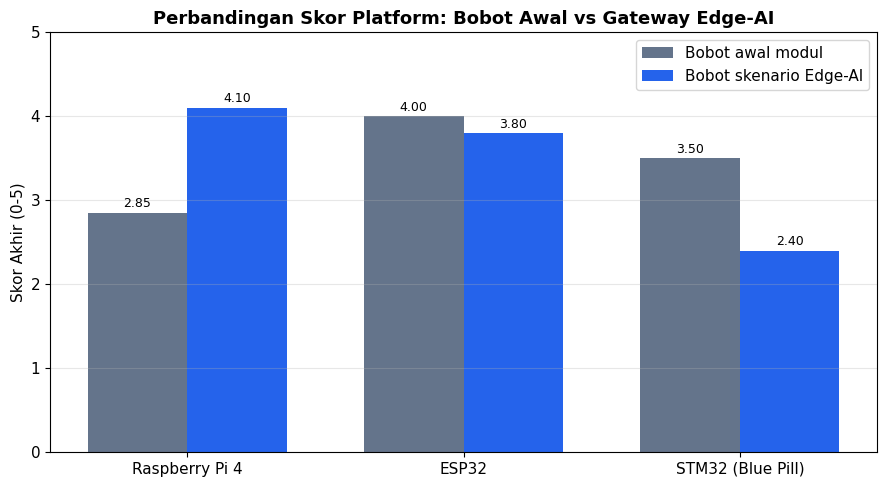

In [3]:
# Visualisasi perbandingan skor sebelum dan sesudah bobot diubah
x = np.arange(len(df_platform))
lebar = 0.36

fig, ax = plt.subplots(figsize=(9, 5))
bars_awal = ax.bar(
    x - lebar / 2, df_platform['Skor Awal (0-5)'], lebar,
    label='Bobot awal modul', color='#64748b'
)
bars_edge = ax.bar(
    x + lebar / 2, df_platform['Skor Edge-AI (0-5)'], lebar,
    label='Bobot skenario Edge-AI', color='#2563eb'
)

for bars in [bars_awal, bars_edge]:
    for bar in bars:
        ax.annotate(
            f'{bar.get_height():.2f}',
            (bar.get_x() + bar.get_width() / 2, bar.get_height()),
            textcoords='offset points', xytext=(0, 4),
            ha='center', fontsize=9
        )

ax.set_xticks(x)
ax.set_xticklabels(df_platform['Platform'])
ax.set_ylim(0, 5)
ax.set_ylabel('Skor Akhir (0-5)')
ax.set_title('Perbandingan Skor Platform: Bobot Awal vs Gateway Edge-AI',
             fontsize=13, fontweight='bold')
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

**Analisis:**

1. Pada bobot awal modul, **ESP32 memperoleh skor 4,00** sehingga menjadi rekomendasi untuk sensor node bertenaga baterai.
2. Pada skenario gateway edge-AI, bobot performa komputasi dinaikkan dari 0,15 menjadi 0,40. Skor Raspberry Pi 4 menjadi **4,10**, sedangkan ESP32 memperoleh **3,80** dan STM32 memperoleh **2,40**.
3. Dengan demikian, **rekomendasi berubah dari ESP32 menjadi Raspberry Pi 4**. Raspberry Pi 4 lebih sesuai untuk skenario ini karena memiliki kemampuan komputasi dan lingkungan pengembangan yang lebih mendukung pemrosesan citra. Kekurangannya adalah konsumsi daya dan biaya yang lebih tinggi.

Bobot yang digunakan merupakan asumsi untuk skenario edge-AI ini. Jika perangkat harus bekerja lama menggunakan baterai, bobot efisiensi daya perlu dinaikkan kembali.

## 2. Modifikasi Hands-On 4: Penambahan Resolusi ADC 16-bit

Kode kuantisasi dari modul ditambahkan dengan resolusi **16-bit**, sedangkan resolusi 8-bit, 10-bit, dan 12-bit tetap dipakai sebagai pembanding. Sinyal analog, tegangan referensi 3,3 V, dan rumus kuantisasi mengikuti simulasi pada modul.

Untuk menghubungkan hasil simulasi dengan sensor suhu, digunakan asumsi bahwa rentang keluaran sensor **0-3,3 V mewakili 0-100°C secara linear**. Asumsi ini hanya untuk mengubah langkah kuantisasi tegangan menjadi satuan suhu.

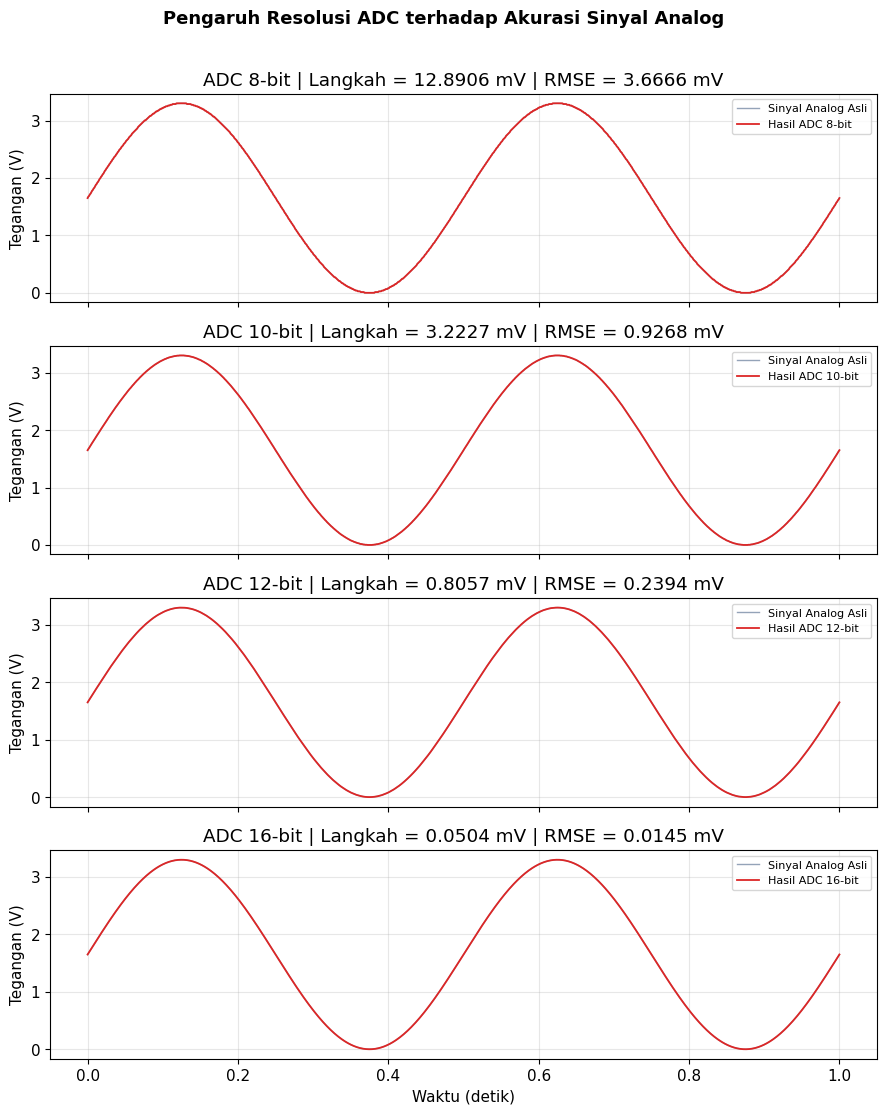

In [4]:
# Modifikasi Hands-On 4: menambahkan resolusi ADC 16-bit

def kuantisasi_adc(sinyal_analog, bit_resolusi, v_ref=3.3):
    level = 2 ** bit_resolusi
    langkah = v_ref / level
    sinyal_terkuantisasi = np.round(sinyal_analog / langkah) * langkah
    return sinyal_terkuantisasi, langkah

# Sinyal analog asli: sinyal sinusoidal 0-3.3 V seperti pada modul
t = np.linspace(0, 1, 1000)
sinyal_asli = 1.65 + 1.65 * np.sin(2 * np.pi * 2 * t)  # osilasi 2 Hz

# Resolusi 16-bit ditambahkan ke daftar resolusi modul
resolusi_list = [8, 10, 12, 16]
fig, axes = plt.subplots(len(resolusi_list), 1, figsize=(9, 11), sharex=True)
rmse_list = []
langkah_list = []

for ax, bit in zip(axes, resolusi_list):
    sinyal_kuantisasi, langkah = kuantisasi_adc(sinyal_asli, bit)
    rmse = np.sqrt(np.mean((sinyal_asli - sinyal_kuantisasi) ** 2))
    rmse_list.append(rmse)
    langkah_list.append(langkah)

    ax.plot(t, sinyal_asli, color='#94a3b8', linewidth=1,
            label='Sinyal Analog Asli')
    ax.plot(t, sinyal_kuantisasi, color='#dc2626', linewidth=1.3,
            label=f'Hasil ADC {bit}-bit')
    ax.set_title(
        f'ADC {bit}-bit | Langkah = {langkah * 1000:.4f} mV | '
        f'RMSE = {rmse * 1000:.4f} mV'
    )
    ax.set_ylabel('Tegangan (V)')
    ax.legend(loc='upper right', fontsize=8)
    ax.grid(alpha=0.3)

axes[-1].set_xlabel('Waktu (detik)')
plt.suptitle('Pengaruh Resolusi ADC terhadap Akurasi Sinyal Analog',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

,Resolusi ADC,Jumlah Level,Langkah Kuantisasi (mV),RMSE (mV),Langkah Suhu (°C),RMSE Suhu (°C)
0,8-bit,256,12.890625,3.666562,0.390625,0.111108
1,10-bit,1024,3.222656,0.926832,0.097656,0.028086
2,12-bit,4096,0.805664,0.239424,0.024414,0.007255
3,16-bit,65536,0.050354,0.014531,0.001526,0.000440


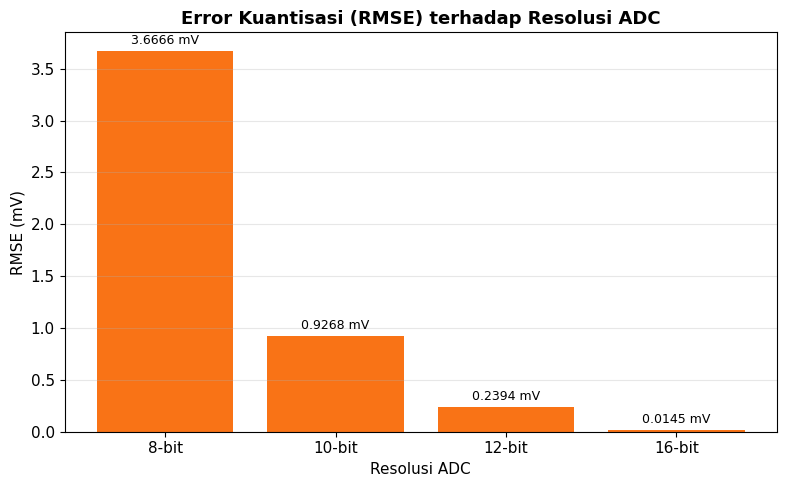

Penurunan RMSE dari 12-bit ke 16-bit: 16.48 kali


In [5]:
# Visualisasi perbandingan error kuantisasi (RMSE)
df_adc = pd.DataFrame({
    'Resolusi ADC': [f'{bit}-bit' for bit in resolusi_list],
    'Jumlah Level': [2 ** bit for bit in resolusi_list],
    'Langkah Kuantisasi (mV)': [nilai * 1000 for nilai in langkah_list],
    'RMSE (mV)': [nilai * 1000 for nilai in rmse_list]
})

# Asumsi pemetaan sensor suhu: 0-3.3 V setara dengan 0-100 derajat C
skala_suhu_per_volt = 100 / 3.3
df_adc['Langkah Suhu (°C)'] = df_adc['Langkah Kuantisasi (mV)'] / 1000 * skala_suhu_per_volt
df_adc['RMSE Suhu (°C)'] = df_adc['RMSE (mV)'] / 1000 * skala_suhu_per_volt

display(df_adc.round(6))

fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(
    df_adc['Resolusi ADC'], df_adc['RMSE (mV)'],
    color='#f97316'
)
for bar, nilai in zip(bars, df_adc['RMSE (mV)']):
    ax.annotate(
        f'{nilai:.4f} mV',
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        textcoords='offset points', xytext=(0, 5),
        ha='center', fontsize=9
    )

ax.set_title('Error Kuantisasi (RMSE) terhadap Resolusi ADC',
             fontsize=13, fontweight='bold')
ax.set_xlabel('Resolusi ADC')
ax.set_ylabel('RMSE (mV)')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

indeks_12 = resolusi_list.index(12)
indeks_16 = resolusi_list.index(16)
print(f'Penurunan RMSE dari 12-bit ke 16-bit: '
      f'{rmse_list[indeks_12] / rmse_list[indeks_16]:.2f} kali')

**Analisis:**

1. Pada simulasi ini, langkah kuantisasi ADC 12-bit adalah sekitar **0,8057 mV**, sedangkan ADC 16-bit sekitar **0,05035 mV**. Resolusi 16-bit menghasilkan langkah yang sekitar **16 kali lebih kecil**.
2. RMSE turun dari sekitar **0,2394 mV (12-bit)** menjadi **0,0145 mV (16-bit)**. Artinya, hasil digital semakin mendekati sinyal analog.
3. Dengan asumsi rentang sensor 0-100°C pada 0-3,3 V, langkah suhu berubah dari sekitar **0,0244°C (12-bit)** menjadi **0,00153°C (16-bit)**. Secara kuantisasi, peningkatannya cukup besar.
4. Namun, peningkatan tersebut **belum tentu signifikan terhadap akurasi suhu nyata**. Akurasi akhir masih dipengaruhi toleransi sensor, noise, kestabilan tegangan referensi, dan rangkaian pengondisi sinyal. Jika ketidakpastian sensor jauh lebih besar daripada 0,0244°C, penggunaan 16-bit tidak otomatis membuat pengukuran suhu menjadi lebih akurat.

**Kesimpulan:** ADC 16-bit memberikan presisi digital yang lebih tinggi. Untuk aplikasi sensor suhu biasa, ADC 12-bit umumnya sudah cukup dari sisi resolusi kuantisasi; ADC 16-bit lebih bermanfaat jika sensor dan rangkaian analog juga mampu memanfaatkan resolusi tambahannya. Simulasi ini merupakan model ideal dan belum memasukkan noise atau kesalahan ADC nyata.

## 3. Modifikasi Hands-On 6: Estimasi Umur Baterai dengan Interval 1 Menit


In [6]:
# Modifikasi Hands-On 6: membandingkan interval 5 menit dan 1 menit
kapasitas_baterai_mAh = 2000  # baterai 2000 mAh


def estimasi_umur_baterai(interval_kirim_detik):
    # Tahapan aktif mengikuti parameter pada modul
    tahapan = [
        {'nama': 'Wake-up + Baca Sensor', 'arus_mA': 30, 'durasi_detik': 0.05},
        {'nama': 'Koneksi WiFi', 'arus_mA': 120, 'durasi_detik': 2.5},
        {'nama': 'Kirim Data (MQTT)', 'arus_mA': 160, 'durasi_detik': 0.3},
        {'nama': 'Deep Sleep', 'arus_mA': 0.01, 'durasi_detik': 0.0}
    ]

    # Durasi deep sleep menjadi sisa dari interval pengiriman
    durasi_aktif = sum(tahap['durasi_detik'] for tahap in tahapan[:-1])
    durasi_deep_sleep = interval_kirim_detik - durasi_aktif
    if durasi_deep_sleep < 0:
        raise ValueError('Interval pengiriman lebih pendek daripada total tahap aktif.')
    tahapan[-1]['durasi_detik'] = durasi_deep_sleep

    df_tahapan = pd.DataFrame(tahapan)
    df_tahapan['Muatan (mAs)'] = (
        df_tahapan['arus_mA'] * df_tahapan['durasi_detik']
    )
    df_tahapan['Muatan (mAh)'] = df_tahapan['Muatan (mAs)'] / 3600

    total_durasi_siklus = df_tahapan['durasi_detik'].sum()
    total_muatan_per_siklus_mAh = df_tahapan['Muatan (mAh)'].sum()
    jumlah_siklus_per_hari = 86400 / total_durasi_siklus
    konsumsi_harian_mAh = jumlah_siklus_per_hari * total_muatan_per_siklus_mAh
    estimasi_umur_hari = kapasitas_baterai_mAh / konsumsi_harian_mAh

    hasil = {
        'Interval Kirim': f'{interval_kirim_detik // 60} menit',
        'Durasi Deep Sleep (detik)': durasi_deep_sleep,
        'Siklus per Hari': jumlah_siklus_per_hari,
        'Muatan per Siklus (mAh)': total_muatan_per_siklus_mAh,
        'Konsumsi per Hari (mAh)': konsumsi_harian_mAh,
        'Estimasi Umur (hari)': estimasi_umur_hari
    }
    return df_tahapan, hasil


# Hasil 5 menit sebagai pembanding dan hasil baru 1 menit
df_tahapan_5menit, hasil_5menit = estimasi_umur_baterai(300)
df_tahapan_1menit, hasil_1menit = estimasi_umur_baterai(60)

df_perbandingan_baterai = pd.DataFrame([hasil_5menit, hasil_1menit])
print('Perbandingan estimasi umur baterai:')
display(df_perbandingan_baterai.round(4))

print('Rincian penggunaan energi untuk interval 1 menit:')
display(df_tahapan_1menit.round(6))

Perbandingan estimasi umur baterai:


,Interval Kirim,Durasi Deep Sleep (detik),Siklus per Hari,Muatan per Siklus (mAh),Konsumsi per Hari (mAh),Estimasi Umur (hari)
0,5 menit,297.15,288.0,0.0979,28.1977,70.9277
1,1 menit,57.15,1440.0,0.0972,140.0286,14.2828


Rincian penggunaan energi untuk interval 1 menit:


,nama,arus_mA,durasi_detik,Muatan (mAs),Muatan (mAh)
0,Wake-up + Baca Sensor,30.00,0.05,1.5000,0.000417
1,Koneksi WiFi,120.00,2.50,300.0000,0.083333
2,Kirim Data (MQTT),160.00,0.30,48.0000,0.013333
3,Deep Sleep,0.01,57.15,0.5715,0.000159


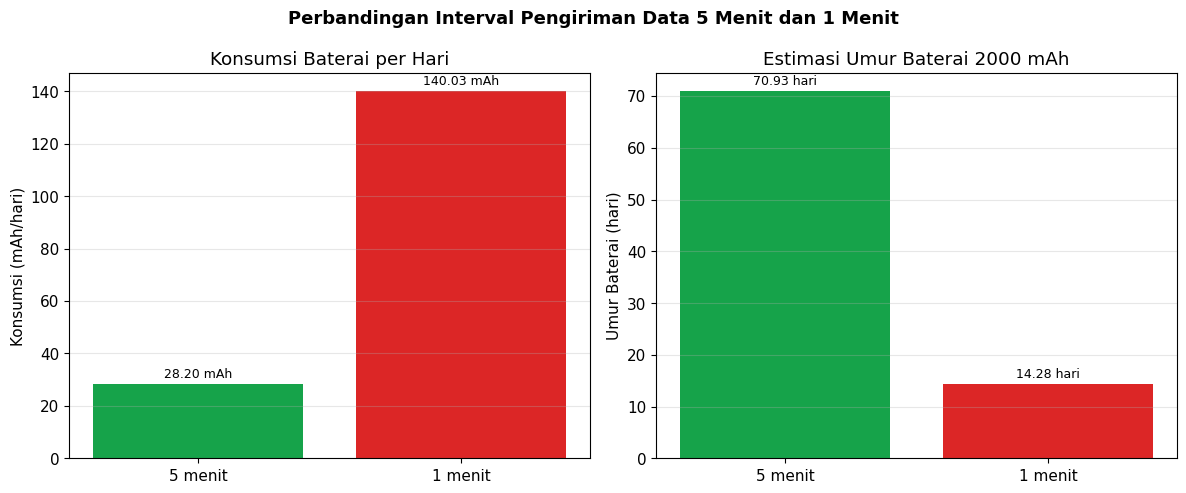

Konsumsi harian meningkat sekitar 4.97 kali.
Estimasi umur baterai berkurang sekitar 79.86%.


In [7]:
# Visualisasi trade-off konsumsi energi dan umur baterai
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Perbandingan konsumsi energi harian
bars_energi = axes[0].bar(
    df_perbandingan_baterai['Interval Kirim'],
    df_perbandingan_baterai['Konsumsi per Hari (mAh)'],
    color=['#16a34a', '#dc2626']
)
for bar in bars_energi:
    axes[0].annotate(
        f'{bar.get_height():.2f} mAh',
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        textcoords='offset points', xytext=(0, 5),
        ha='center', fontsize=9
    )
axes[0].set_title('Konsumsi Baterai per Hari')
axes[0].set_ylabel('Konsumsi (mAh/hari)')
axes[0].grid(axis='y', alpha=0.3)

# Perbandingan estimasi umur baterai
bars_umur = axes[1].bar(
    df_perbandingan_baterai['Interval Kirim'],
    df_perbandingan_baterai['Estimasi Umur (hari)'],
    color=['#16a34a', '#dc2626']
)
for bar in bars_umur:
    axes[1].annotate(
        f'{bar.get_height():.2f} hari',
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        textcoords='offset points', xytext=(0, 5),
        ha='center', fontsize=9
    )
axes[1].set_title('Estimasi Umur Baterai 2000 mAh')
axes[1].set_ylabel('Umur Baterai (hari)')
axes[1].grid(axis='y', alpha=0.3)

plt.suptitle('Perbandingan Interval Pengiriman Data 5 Menit dan 1 Menit',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

penurunan_umur_persen = (
    (hasil_5menit['Estimasi Umur (hari)'] - hasil_1menit['Estimasi Umur (hari)'])
    / hasil_5menit['Estimasi Umur (hari)'] * 100
)
kenaikan_konsumsi = (
    hasil_1menit['Konsumsi per Hari (mAh)']
    / hasil_5menit['Konsumsi per Hari (mAh)']
)
print(f'Konsumsi harian meningkat sekitar {kenaikan_konsumsi:.2f} kali.')
print(f'Estimasi umur baterai berkurang sekitar {penurunan_umur_persen:.2f}%.')

**Analisis:**

1. Pada interval 5 menit, perangkat mengirim data **288 kali per hari** dan estimasi baterainya sekitar **70,93 hari** (dibulatkan menjadi 71 hari), sesuai hasil simulasi modul.
2. Pada interval 1 menit, perangkat mengirim data **1.440 kali per hari**. Durasi *deep sleep* berkurang dari 297,15 detik menjadi 57,15 detik per siklus. Estimasi umur baterai turun menjadi sekitar **14,28 hari**.
3. Konsumsi energi harian meningkat dari sekitar **28,20 mAh** menjadi **140,03 mAh**, atau sekitar 4,97 kali lebih besar. Umur baterai berkurang sekitar 79,86%.
4. **Trade-off:** interval 1 menit membuat pemantauan lebih responsif karena data diperbarui lebih sering dan keterlambatan mendeteksi perubahan kondisi menjadi lebih kecil. Namun, perangkat lebih sering mengaktifkan WiFi dan mengirim MQTT sehingga konsumsi baterai meningkat dan perangkat perlu lebih sering diisi ulang atau mengganti baterai.

**Kesimpulan:** Interval 1 menit cocok ketika perubahan kondisi harus diketahui lebih cepat. Untuk pemantauan yang tidak membutuhkan respons cepat, interval 5 menit lebih hemat energi dan memberikan umur baterai lebih panjang. Hasil ini merupakan estimasi berdasarkan arus dan durasi tiap tahap dari modul, bukan jaminan umur baterai aktual.